<left>
    <img src="https://kpi.ua/files/images/kpi.png" width="300" alt="kpi logo"  />
</left>

# Курсова робота. Метод Марквардта
### Виконав Костенко Владислав, група КМ-82
### Керівник: викладач Норкін Богдан Володимирович

## Зміст
* Постановка задачі
* Опис методів
* Розв'язання задачі, отримані обчислення, візуалізація
  * Завдання 1
  * Завдання 2
* Висновки
* Автори
* Використані джерела



## Постановка задачі
Задача являє собою реалізацію метода Марквардта для вирішення задачі безумовної оптимізації та застосування методу зовнішньої точки для перетворення задачі умовної оптимізації в задачу безумовної для подальшого її вирішення методом Марквардта

## Опис методів
### Метод Марквардта
Метод являє собою комбінацію методу найшвидшого спуску і методу Ньютона, в якій вдало поєднуються позитивні властивості обох методів. Далеко від екстремуму найбільш ефективний напрямок руху визначається методои градіентного спуску, а в околиці точки $x^* $- методом Ньютона. В цьому і полягає ідея методу Марквардта.

На відміну від методу Ньютона в методі Марквардта знаходження $x_{k+1}$ визначається за формулою 
<li>$x_{(k+1)} = x_{(k)} - (H+\lambda*I)^{-1}*\Delta f(x_{(k)}) $</li>

де I - одинична матриця; H - матриця Гессе, $\lambda$ - параметр, що дозволяє регулювати стратегію пошуку, змінюючи її від градієнтної на початкових етапах до ньютонівської - поблизу екстремальної точки(так званий damping parameter).

Для цього на початковій стадії пошуку прийнято брати велике значення параметра $\lambda$ (наприклад, $10^3, 10^4$ і т.д.).
Якщо значення функції у $x^{k+1}$ більше за відповідне у $x^k$ цей параметр прийнято збільшувати на певну константу, у протилежному випадку зменшувати (у даній роботі ця константа - 2)

На відміну від метода Ньютона матриця Гессе не обов'язково має бути додатня, щоб знайти вірний напрямок.

Алгоритм методу Марквардта характеризується відносною простотою, властивістю зменшення значень цільової функції з кожною ітерацією, високою швидкістю збіжності в околиці точки мінімуму, а також відсутністю процедури одновимірного пошуку.

### Метод Левенберга - Марквардта
Метод є модифікацією методу Марквардта для задачі найменших квадратів.
Ітеративна формула 
<li>$x_{(k+1)} = x_{(k)} - (J(x_{(k)})^T*J(x_{(k)})+\lambda*I)^{-1}*J(x_{(k)})^T*f(x_{(k)}) $</li>

Як можемо побачити, у модифікації матриця Гессе представлена добутком Якобіанів J, що значно спрощує розрахунки, тоді як ми не маємо вираховувати 2гі похідні. У якості критерію зупики зазвичай використовується досягнення фунції мінімуму або при $ \Vert \Delta x \Vert < \epsilon $. У даній роботі будемо використовувати другий критерій.
Метод також може бути переформульований, як метод довірчих інтервалів.

### Метод зовнішньої точки
Метод штрафних функцій - метод вирішення задач умовної оптимізації при обмеженнях $c_j(x)>0$.
Задачу можна сформулювати, як мінімізації функції Z, ка приймає вигляд $ Z = \phi (x,r) = f(x) + P(x) $,
де P - певна функція, що 'штрафує' функцію Z при порушенні обмежень.
Метод зовнішньої точки - це штрафний метод при знаходженні початкової точки поза допустимої області з функцією штрафа типу квадрата зрізки, тобто, якщо обмеження виконується - значення функції дорівнює нулю, або в іншому випадку - квадрату заданого обмеження помноженого на коефіціент R.

## Розв'язання задачі, отримані обчислення, візуалізація

### Завдання 1.
Дослідити збіжність методу Марквардта при мінімізації функції Розенброка  в залежності від:
<ol>
    <li>Величини кроку h при обчисленні першої та другої похідних.</li>
    <li>Схеми обчислення першої та другої похідних.</li>
    <li>Вигляду критерію закінчення. </li>
    <li>Значення параметрів методу.</li>
    <li>Модифікації методу для задач типу $ \sum f_i^2 $  </li>
</ol>

Імпортуємо необхідні бібліотеки

In [1]:
import numpy as np
import scipy
from numpy.linalg import norm, inv
import numdifftools as nd
import pandas as pd
import warnings
from pprint import pprint
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

Задамо функцію Розенброка 
$ (1-x)^2 + 100*(y-x^2)^2 $
та її розклад, як суму квадратів для розрахунку матриці Якобі <br>
У якості початкової точки візьмемо точку $x^{(0)} = (-1,1)$

In [2]:
#initialize rosenbrock function
rosenbrock = lambda x: (1-x[0])**2 + 100*(x[1]-x[0]**2)**2
#rosenbrock as sum of squares
def rosenbrock_squares(x):
     return np.array([(1-x[0]), 10*(x[1]-x[0]**2)])
#x0 = (0,0)
x0 = np.array([-1,1])

Використаємо різні h задані нижче:

In [3]:
#1 task
h = [0.001, 0.0001, 0.00001] 

Використаємо центральну, ліву і центральні схеми розрахунку похідних

In [4]:
#task 2
diff_methods = ['central', 'forward', 'backward']

Використаємо наступні критерії зупинки алгоритму:
<li>$
\frac {\Vert x^{k+1}-x^k \Vert }{\Vert x^k \Vert}<=\epsilon\\
\vert f(x^{k+1})-f(x^k)\vert<=\epsilon $
 </li>

або
<li>$ \Vert \nabla f(x^k)\Vert<=\epsilon $</li>

In [5]:
#3 task
def criterion1(xk, xk1, fxk1,fxk, epsilon, gradient):
    first = norm(xk1-xk) / norm(xk) <=epsilon
    second = abs(fxk1-fxk) / abs(fxk) <=epsilon
    return first and second

def criterion2(xk, xk1, fxk1,fxk2, epsilon, gradient):
    return norm(gradient)<=epsilon

criterion_arr = [criterion1, criterion2]

Задамо різні damping параметри

In [6]:
#4 task
lambd_arr = [10**3, 1, 0.001]
i_arr = [False, True]

Використаємо модифікацію Левенберга - Марквардта для функцій вигляду $ \sum f_i^2 $


In [7]:
#5 task

modification_arr = [False, True]

Задаємо функцію, яка приймає такі параметри
<li>f - цільова функція (за замовчуванням - функція Розенброка)</li>
<li>x0 - початкова точка (за замовчуванням - $ x = (0, 0)) $</li>
<li>method - метод обчислення похідних (за замовчуванням - центральна схема)</li>
<li>lambd - довжина кроку (за замовчуванням - $ \lambda = 10^3 $)</li>
<li>criterion - критерій закінчення (за замовчуванням - перший критерій)</li>
<li>modification - використання модифікації Левенберга-Марквардта чи ні (за замовчуванням - ні)</li>
<li>epsilon (за замовчуванням - 0.00005)</li>
<li>max_iter - максимальна кількість ітерацій (за замовчуванням - 1000)</li>

Словник з параметрами по замовчуванню представлений нижче:

In [8]:
default_params = {
    'f': rosenbrock,
    'f_sq': rosenbrock_squares,
    'x0':x0,
    'h':h[0],
    'method': diff_methods[0],
    'criterion':criterion_arr[0],
    'lambd': lambd_arr[0],
    'modification':False,
    'epsilon': 0.00005,
    'max_iter': 1000,
}

Задаємо метод Марквардта за формулою:

In [9]:
def marquardt(f, x0, h,  method, lambd, criterion, epsilon, max_iter):
    xk = x0
    I = np.ones((2,2))
    X = []
    grad = lambda x,f=f, h=h, method=method: nd.Gradient(f, step=h, method =method)(x)
    hesse = lambda x, f=f, h=h, method=method: nd.Hessian(f, step=h, method =method)(x)

    for i in range(max_iter):
        X.append(xk)
        fxk = f(xk)

        gradient = grad(xk)
        hessian = hesse(xk)
        xk1 = xk - inv(hessian+(lambd*I)).dot(gradient)
        fxk1 = f(xk1)
        if criterion(xk, xk1,fxk1,fxk,epsilon,gradient):
            X.append(xk1)
            return X
        if f(xk1) > f(xk):
            lambd = 2*lambd
        else:
            lambd = lambd/2
        xk = xk1
        
    return X


Задаємо модифікацію Левенберга - Марквардта. У якості критерію закінчення для методу Левенберга-Марквардта використаємо 
$ \Vert \Delta x \Vert < \epsilon $

In [10]:
def levenberg_marquardt(f, f_sq, x0, h, method, lambd, criterion, epsilon, max_iter):

    xk = x0
    I = np.ones((2,2))
    X = []
    grad = lambda x,f=f, h=h, method=method: nd.Gradient(f, step=h, method =method)(x)
    jacob = lambda x,f=f_sq,h=h,method=method: nd.Jacobian(f, step=h, method =method)(x)
    for i in range(max_iter):
        X.append(xk)

        gradient = grad(xk)
        jacobian = jacob(xk)
        
        xk1 = xk - inv(jacobian.T.dot(jacobian)+(lambd*I)).dot(jacobian.T).dot(f_sq(xk))
        if norm(xk1-xk) <epsilon:
            X.append(xk1)
            return X
        if f(xk1) > f(xk):
            lambd = 2*lambd
        else:
            lambd = lambd/2
        xk = xk1
        
    return X


Створимо клас, який приймає необхідні нам параметри і повертає точку і значення функції у цій точці на кожній ітерації.
Методи:
<li>optimize - повертає вищезазначені значення</li>
<li>get_df - перетворює значення у тип DataFrame для быльш читаємого вигляду</li>
<li>get_last_iter - повертає значення на останній ітерації (для зручного представлення і перевірки різних параметрів методу будемо використовувати саме цей метод)</li>

In [ ]:
class Optimizer:

    def __init__(self, f, f_sq, x0, h, method, lambd, criterion, modification, epsilon, max_iter,constraints=None):
        self.f = f
        self.f_sq = f_sq
        self.x0 = x0
        self.h = h
        self.method = method
        self.lambd = lambd
        self.criterion = criterion
        self.modification = modification
        self.epsilon = epsilon
        self.max_iter = max_iter

    def optimize(self):
        if self.modification:
            X = levenberg_marquardt(self.f, self.f_sq, self.x0, self.h, self.method, self.lambd, self.criterion, self.epsilon, self.max_iter)
        elif not self.modification:
            X = marquardt(self.f,  self.x0, self.h, self.method, self.lambd, self.criterion, self.epsilon, self.max_iter)

        return X
    
    def get_df(self):
        X = self.optimize()
        df = pd.DataFrame(X , columns=('x1','x2'))
        df.index.name = 'Iteration'
        df['f(x)'] = self.f([df.x1,df.x2])
        return df

    def get_last_iter(self):
        return self.get_df().iloc[[-1]]

Перевіримо кількість ітерацій з різними значеннями h:

In [12]:
for h_v in h:
    optimizer = Optimizer(**default_params)
    print(f'h = {h_v}')
    optimizer.h = h_v
    print(optimizer.get_last_iter())
    print('\n')

h = 0.001
               x1      x2          f(x)
Iteration                              
25         0.9998  0.9996  3.998401e-08


h = 0.0001
                 x1        x2          f(x)
Iteration                                  
26         0.999998  0.999996  3.999984e-12


h = 1e-05
            x1   x2          f(x)
Iteration                        
27         1.0  1.0  3.999992e-16




Як можемо побачити з зменшенням кроку, збільшується точність обчислень і кількість ітерацій

Перевіримо кількість ітерацій з різними схемами обчислення:

In [13]:
for diff in diff_methods:
    optimizer = Optimizer(**default_params)
    print(f'Differentiation method  = {diff}')
    optimizer.method = diff
    print(optimizer.get_last_iter())
    print('\n')

Differentiation method  = central
               x1      x2          f(x)
Iteration                              
25         0.9998  0.9996  3.998401e-08


Differentiation method  = forward
               x1        x2          f(x)
Iteration                                
27         1.0004  1.000801  1.603657e-07


Differentiation method  = backward
               x1      x2          f(x)
Iteration                              
27         1.0004  1.0008  1.598853e-07




Як бачимо, у нашому випадку різні схеми не впливають на кількість ітерацій. Центральна схема має більшу точність.

Перевіримо кількість ітерацій з різними критеріями закінчення:

In [14]:
for criterion in criterion_arr:
    optimizer = Optimizer(**default_params)
    print(f'Criterion  = {criterion.__name__}')
    optimizer.criterion = criterion
    print(optimizer.get_last_iter())
    print('\n')

Criterion  = criterion1
               x1      x2          f(x)
Iteration                              
25         0.9998  0.9996  3.998401e-08


Criterion  = criterion2
               x1      x2          f(x)
Iteration                              
23         0.9998  0.9996  4.006207e-08




Перевіримо кількість ітерацій з різними параметрами $\lambda$:

In [15]:
for lambd in lambd_arr:
    optimizer = Optimizer(**default_params)
    print(f'Lambda  = {lambd}')
    optimizer.lambd = lambd
    print(optimizer.get_last_iter())
    print('\n')

Lambda  = 1000
               x1      x2          f(x)
Iteration                              
25         0.9998  0.9996  3.998401e-08


Lambda  = 1
               x1      x2          f(x)
Iteration                              
15         0.9998  0.9996  3.998401e-08


Lambda  = 0.001
               x1      x2          f(x)
Iteration                              
6          0.9998  0.9996  3.998400e-08




Як бачимо зі зменшенням початкового значення $\lambda$ зменшується кількість ітерацій, що є логічним, так як при меншому значенні цього параметру метод більше нагадує метод Ньютона, який має швидку сходимість для функції Розенброка.

Перевіримо кількість ітерацій з модифікацією та без:

In [16]:
for mod in modification_arr:
    optimizer = Optimizer(**default_params)
    temp = 'Levenberg-Marquardt' if mod else 'Marquardt'
    print(f'Method  = {temp}')
    optimizer.modification = mod
    print(optimizer.get_last_iter())
    print('\n')

Method  = Marquardt
               x1      x2          f(x)
Iteration                              
25         0.9998  0.9996  3.998401e-08


Method  = Levenberg-Marquardt
            x1   x2          f(x)
Iteration                        
22         1.0  1.0  1.028636e-15




Як можемо побачити модифікація є більш точною і потребує меншої кількості ітерацій для нашої задачі.

Розробимо клас для візуалізації методу

In [17]:
class Plotter:
    def __init__(self,f,x1,x2, title, constraints = None):
        self.f = f
        self.x1 = x1
        self.x2 = x2
        self.title = title
        self.constraints = constraints

    def plot(self):
        x1 = np.linspace(-1.0- 3*self.x1[0], 2.0+ 3*self.x1[0], 1000)
        x2 = np.linspace(-1.0- 3*self.x2[0], 2.0+ 3*self.x2[0], 1000)
        X1, X2 = np.meshgrid(x1, x2)
        Y = self.f([X1,X2])

        fig = plt.figure(figsize=(6, 6), dpi=80)
        cp = plt.contour(X1, X2, Y, colors='black', linestyles='dashed', linewidths=1)
        plt.clabel(cp, inline=1, fontsize=10)
        cp = plt.contourf(X1, X2, Y, )
        mp = plt.plot(self.x1,self.x2, color='r', marker = 'o', ms = 2)

        plt.xlabel('X1')
        plt.ylabel('X2')
        plt.title(self.title)
        print(f'Number of iterations: {len(self.x1)-1}')
        plt.show()

Візуалізація методу Марквардта

Number of iterations: 25


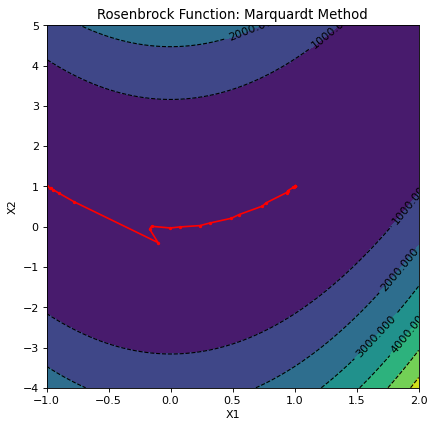

In [18]:
optimizer = Optimizer(**default_params)
df = optimizer.get_df()
plotter = Plotter(rosenbrock, df['x1'], df['x2'],'Rosenbrock Function: Marquardt Method')

plotter.plot()

Візуалізація методу Левенберга-Марквардта

Number of iterations: 22


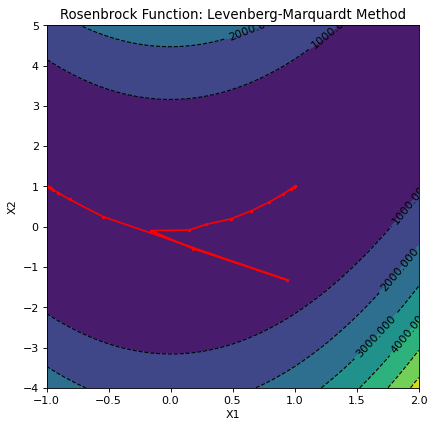

In [19]:
optimizer = Optimizer(**default_params)
optimizer.modification = True
df = optimizer.get_df()
plotter = Plotter(rosenbrock, df['x1'], df['x2'],'Rosenbrock Function: Levenberg-Marquardt Method')

plotter.plot()

### Завдання 2.
Використати метод штрафних функцій (метод зовнішньої точки) для умовної оптимізації в залежності від:
<ol>
    <li>Розташування локального мінімума (всередині/поза допустимою областю).</li>
    <li>Виду допустимої області (випукла/невипукла).</li>
    <li>Розташування точки мінімума поза допустимої області.</li>
</ol>


Використаємо вже заданий метод Марквардта для знаходження локального мінімуму</br>
У якості цільової функції використаємо функцію Розенброка 
$ (1-x)^2 + 100*(y-x^2)^2 $



Задамо функцію, яка буде реалізовувати поставлений метод. У якості початкової точки на цей раз візьмемо точку $x^{(0)} = (1.5, 1.5)$. У якості константи r візьмемо значення 1, 100 і 1000. Для реалізації методу зовнішньої точки будемо кожен раз створювати нову функцію, що перевіряє порушення заданих нами обмежень.

In [24]:
def constrained(f, x_0 = np.array([1.5,1.5])):
    r_arr = [1,100,1000]
    for r in r_arr:
        optimizer = Optimizer(**default_params)
        print(f'r = {r}')
        f_r = lambda x, r=r: f(x,r)
        #optimizer.criterion = lambda xk, xk1,fxk1,fxk,epsilon,gradient: False
        optimizer.f = f_r
        optimizer.x0= x_0
        df = optimizer.get_df()
        plotter = Plotter(f_r, df['x1'], df['x2'],'Constrained Rosenbrock Function')
        print(optimizer.get_last_iter())
        plotter.plot()
        print('\n')

Перевіримо задачу умовної оптимізації мінімізації функції Розенброка з загальноприйнятими її обмеженнями:
<li>$(x-1)^3-y+1<0 і $x+y-2<0$</li>
<li>$x^2 + y^2 < 2$</li>

У обох випадках глобальний мінімум знаходиться в точці $ x^* = (1,1) $ 

$x^2 + y^2 < 2$

r = 1
                 x1        x2          f(x)
Iteration                                  
17         0.999994  0.999989  1.188892e-09
Number of iterations: 17


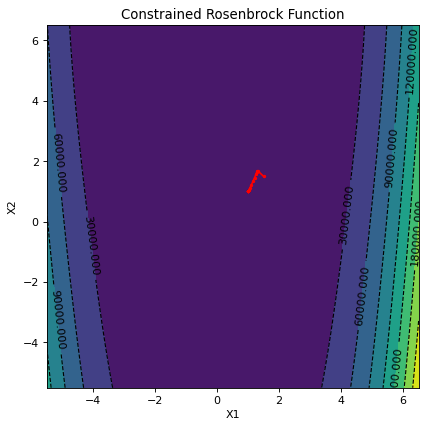



r = 100
            x1   x2          f(x)
Iteration                        
11         1.0  1.0  2.220248e-10
Number of iterations: 11


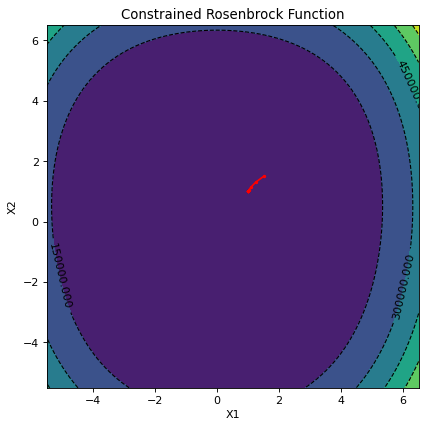



r = 1000
            x1   x2          f(x)
Iteration                        
8          1.0  1.0  1.112067e-09
Number of iterations: 8


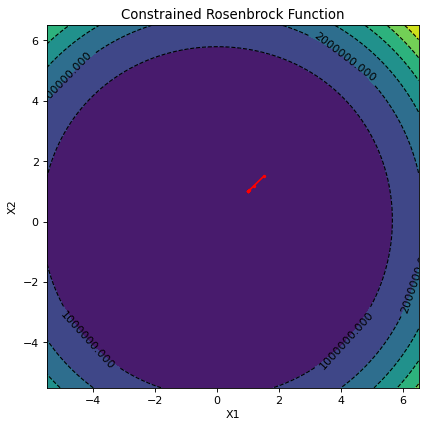

In [25]:
def rosenbrock_c_1(x,r):
    c = 2 - x[0]**2 -x[1]**2 >0
    if isinstance(c,bool):
        if c:
            return (1-x[0])**2 + 100*(x[1]-x[0]**2)**2
    return (1-x[0])**2 + 100*(x[1]-x[0]**2)**2 + r*(2 - x[0]**2 -x[1]**2)**2

constrained(rosenbrock_c_1)

$(x-1)^3-y+1<0 $ і $x+y-2<0$

r = 1
                 x1        x2          f(x)
Iteration                                  
18         0.999985  0.999972  2.908019e-09
Number of iterations: 18


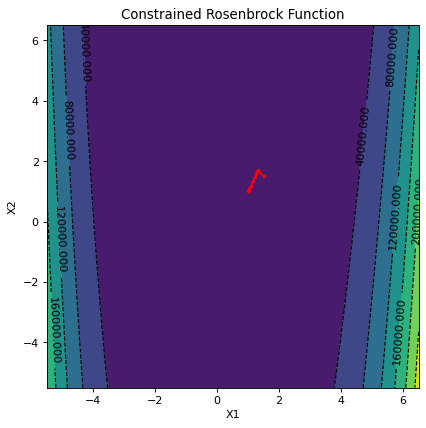



r = 100
            x1   x2          f(x)
Iteration                        
12         1.0  1.0  8.553099e-11
Number of iterations: 12


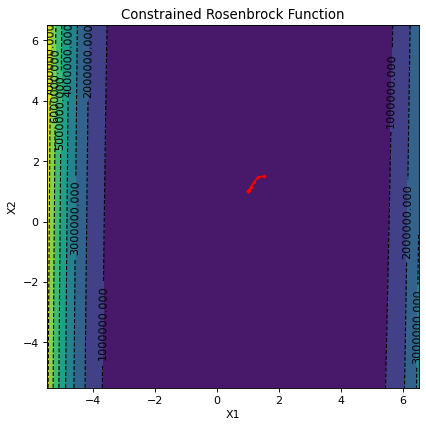



r = 1000
            x1   x2          f(x)
Iteration                        
9          1.0  1.0  3.648836e-11
Number of iterations: 9


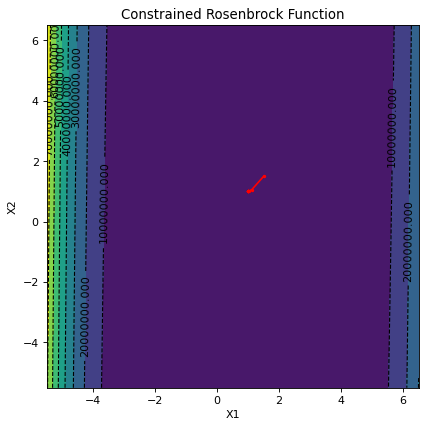

In [26]:
def rosenbrock_c_2(x,r):
    c1 = -(x[0]-1)**3 +x[1] -1 >0
    c2 = -x[0] - x[1] + 2 > 0
    if isinstance(c1,bool) and isinstance(c2,bool):
        if c1 and c2:
            return (1-x[0])**2 + 100*(x[1]-x[0]**2)**2
        elif c1:
            return (1-x[0])**2 + 100*(x[1]-x[0]**2)**2 + r*(-x[0] - x[1] + 2)**2
        elif c2:
            return (1-x[0])**2 + 100*(x[1]-x[0]**2)**2 + r*(-(x[0]-1)**3 +x[1] -1)**2

    return (1-x[0])**2 + 100*(x[1]-x[0]**2)**2 + r*(-(x[0]-1)**3 +x[1] -1)**2 + r*(-x[0] - x[1] + 2)**2

constrained(rosenbrock_c_2)

Як можемо побачити у обох випадках метод успішно зміг досягти глобального мінімуму

Перевіримо, як метод буде себе поводити, якщо мінімум не буде належати допустимій області, а саме при обмеженні $x^2 + y^2 < 1$. Очікується, що метод має зупинитися на границі допустимої області.

r = 1
                 x1        x2      f(x)
Iteration                              
15         0.801499  0.641705  0.042387
Number of iterations: 15


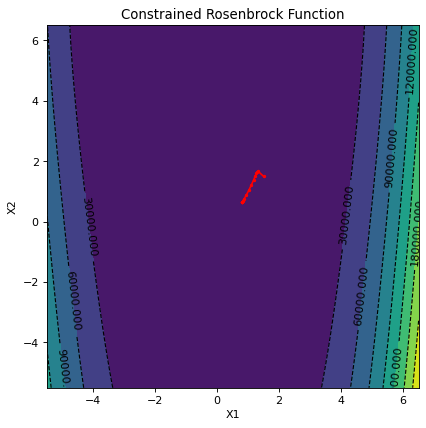



r = 100
                 x1       x2      f(x)
Iteration                             
9          0.786587  0.61797  0.045638
Number of iterations: 9


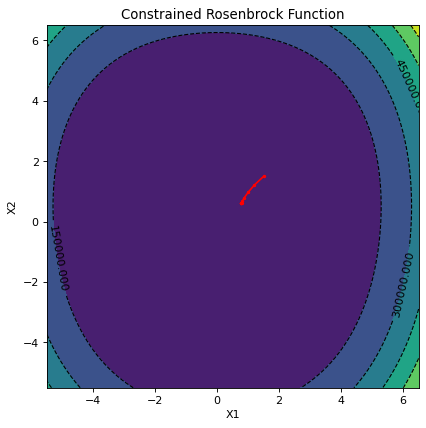



r = 1000
                 x1        x2      f(x)
Iteration                              
7          0.786432  0.617725  0.045671
Number of iterations: 7


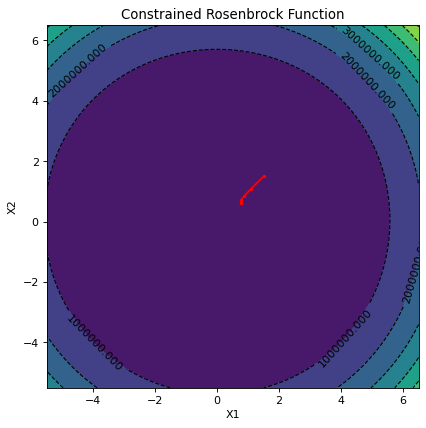

In [27]:
def rosenbrock_c_1(x,r):
    c = 1 - x[0]**2 -x[1]**2 >0
    if isinstance(c,bool):
        if c:
            return (1-x[0])**2 + 100*(x[1]-x[0]**2)**2
    return (1-x[0])**2 + 100*(x[1]-x[0]**2)**2 + r*(1 - x[0]**2 -x[1]**2)**2

constrained(rosenbrock_c_1)

Як і очікувалося метод зупинився на границі області

## Автори

Костенко Владислав, КМ-82

## Висновки
У ході виконання курсової роботи за допомогою мови Python був реалізований метод Марквардта для задач безумовної оптимізації.
Також був реалізована модифікація Левенберга-Марквардта для задач найменших квадратів і метод внутрішньої точки для перетворення задачі умовної оптимізації до задач безумовної для подальшого їх вирішення методом Марквардта.
Реалізація методу є досить гнучкою і приймає багато різних параметрів, що дозволять нам побачити, як працює вищезазначений метод при різних значеннях кроку h при обчисленні першої та другої похідних, схеми обчислення першої та другої похідних, вигляду критерію закінчення та значенню параметру $\lambda$. У якості тестової функції була взята функція Розенброка для задач безумовної і умовної оптимізації.

Величини кроку h при обчисленні першої та другої похідних.
Схеми обчислення першої та другої похідних.
Вигляду критерію закінчення.
Значення параметрів методу.
Модифікації методу для задач типу $ \sum f_i^2 $

При вирішенні задачі безумовної оптимізації функції Розенброка, як і очікувалось, виявилося, що метод потребує більше ітерацій при зменшенні кроку h. Ліва і права схеми для обчислення похідних не показали значної різниці при розрахунках, хоча центральна схема показала більшу точність. Різні критерії закінчення не сильно вплинули на точність або кількість ітерацій методу. Зменшення параметру $\lambda$, дало значне зменшення кількості ітерацій, бо як і зазначалось, чим менше цей параметр - тим більше метод Марквардта схожий на метод Ньютона. Все ж, рекомендується брати $\lambda$ більш великим, бо це позбавляє його недоліку метода Ньютона, що може не зійтись при поганому значенні початкової точки.
Метод Левенберга-Марквардта показав себе краще для нашої задачі, знайшовши точку мінумуму при меншій кількості ітерацій та з значно більшою точністю.

Для задачі умовної оптимізації функції Розенброка методом зовнішньої точки були взяті такі обмеження:

<li> $(x-1)^3-y+1<0 і $x+y-2<0$</li>

<li> $x^2 + y^2 < 2$</li>

<li> $x^2 + y^2 < 1$</li>

У якості параметру R були взяті значення 1, 100 і 1000. Як і очікувалось, при більшому значенні R, функція більше 'штрафує' метод і тому, він сходиться при меншій кількості ітерацій.

Для візуалізації кожного з методів був розроблений спеціальний клас, що показує кожну ітерацію методів.

Модифікацією даної реалізації можна назвати зміну константи, яка впливає на значення $\lambda$

Модифікацію даного методу можна назвати, зазначену в літературі заміну одниничної матриці I на добуток $J * J^T$

## Використані джерела
<a href ="https://studfile.net/preview/4243517/">
ЧИСЛЕННЫЕ МЕТОДЫ ОПТИМИЗАЦИИ. В.И. Рейзлин
</a>

<a href ="https://studfile.net/preview/4243517/">
Методы многомерной безусловной минимизации. В. П. Северин
</a>

http://www.machinelearning.ru/wiki/index.php?title=%D0%90%D0%BB%D0%B3%D0%BE%D1%80%D0%B8%D1%82%D0%BC_%D0%9B%D0%B5%D0%B2%D0%B5%D0%BD%D0%B1%D0%B5%D1%80%D0%B3%D0%B0-%D0%9C%D0%B0%D1%80%D0%BA%D0%B2%D0%B0%D1%80%D0%B4%D1%82%D0%B0

http://www.machinelearning.ru/wiki/index.php?title=%D0%9C%D0%B5%D1%82%D0%BE%D0%B4_%D1%88%D1%82%D1%80%D0%B0%D1%84%D0%BD%D1%8B%D1%85_%D1%84%D1%83%D0%BD%D0%BA%D1%86%D0%B8%D0%B9

<a href ="http://www.mathnet.ru/links/3d1664da335f1ad762208d91a55b5d6c/vtamu98.pdf">
Levenberg–Marquardt method for unconstrained optimization
Alexey F. IZMAILOV, Alexey S. KURENNOY, Petr I. STETSYUK
</a>

https://ru.wikipedia.org/wiki/%D0%A2%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D1%8B%D0%B5_%D1%84%D1%83%D0%BD%D0%BA%D1%86%D0%B8%D0%B8_%D0%B4%D0%BB%D1%8F_%D0%BE%D0%BF%D1%82%D0%B8%D0%BC%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D0%B8

https://ru.wikipedia.org/wiki/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4_%D1%88%D1%82%D1%80%D0%B0%D1%84%D0%BE%D0%B2